# PXR dose-response: raw plate data → 4PL fit → potency + 2D structures

**Goal.** Take raw luciferase plate data from the OpenADMET/Octant PXR HTChem blog-post repository (experiment **OPA_PXR-046**: GAL4-PXR reporter cells, 9-point titration, 5 nM – 50 µM), extract 20 compounds, fit a four-parameter logistic (4PL) curve to each, and plot every curve next to its 2D structure on identical axes.

**Assay and source.** PXR agonism in a GAL4-PXR reporter cell line (1536-well plates, 18–24 h compound incubation, Nano-Glo luciferase readout). The assay protocol, raw data and the authors' fits are in [OpenADMET/octant-pxr-htchem-blogpost](https://github.com/OpenADMET/octant-pxr-htchem-blogpost); the accompanying blog post, [Navigating PXR Chemical Space with High-Throughput Chemistry and Standard-Free Quantification](https://openadmet.github.io/octant-pxr-htchem-blogpost/), describes the experiments and the CAD yield correction of crude-sample potencies (not applied here). The blog post does not describe the curve fitting; the fit below is my own.

| Step | What happens | Output |
|---|---|---|
| 1–3 | Download raw wells, structures and the authors' fits | `data/source_046_stats/`, `data/source_046_cdd/` |
| 4–6 | Select 20 compounds, save their raw wells as TSV, read it back | `data/pxr_046_raw_20cpds.tsv`, `data/pxr_046_structures_20cpds.tsv` |
| 7–8 | Fit a 4PL curve per compound | `data/pxr_046_fit_results_20cpds.tsv` |
| 9 | Plot curves + structures | `figures/pxr_046_dose_response_20cpds.png` / `.pdf` |
| 10 | Cross-check against the authors' published fits | inline figure |

**Units.**
- Concentration: µM (the raw file stores mol/L in `chem_m`).
- Response: luciferase signal normalised per plate, dimensionless. ≈ 0 at the negative-control (vehicle) level and 1 = the positive-control response (the dataset README states Emax is "normalized to the positive control").
- Potency: EC₅₀ in µM and pEC₅₀ = −log₁₀(EC₅₀ / M); higher pEC₅₀ = more potent.

## 1. Setup
Imports, source URLs, output paths and the plotting style (colours from the dataviz reference palette: blue = data, orange = fit, neutral ink for all text).

In [1]:
import io
from pathlib import Path
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from PIL import Image
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from scipy import optimize, stats

# --- sources (OpenADMET/octant-pxr-htchem-blogpost, data/raw/drc/htchem-libraries/)
REPO = ("https://raw.githubusercontent.com/OpenADMET/octant-pxr-htchem-blogpost/main/"
        "data/raw/drc/htchem-libraries/")
RAW_URL = REPO + "OPA_PXR-046_55547_processed-data_OCNT-0002416/stats.tsv"   # raw per-well data
CDD_URL = REPO + urllib.parse.quote(                                          # SMILES + authors' fits
    "CDD CSV Export - 2026-04-22 Run of luci_drc_PXR OCNT-0002416 Mini-Am Library.csv")

# --- outputs
DATA, FIGS = Path("data"), Path("figures")
RAW_TSV = DATA / "pxr_046_raw_20cpds.tsv"
STRUCT_TSV = DATA / "pxr_046_structures_20cpds.tsv"
FIT_TSV = DATA / "pxr_046_fit_results_20cpds.tsv"
N_COMPOUNDS = 20

# --- 4PL fit settings (step 7)
BOTTOM = 0.0                # baseline fixed at the negative-control level (luci_norm is 0 there by construction)
TOP_MAX = 2.0               # cap on the plateau, as a fraction of the positive control (library Emax max is 1.77)
HILL_BOUNDS = (0.3, 5.0)

# --- style: dataviz reference palette (blue = measured data, orange = fit)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0dc"
plt.rcParams.update({
    "font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 1.0, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 2. Load the raw plate data
`stats.tsv` has one row per well: plate position, compound, concentration (`chem_m`, mol/L), raw luminescence (`luci`, RLU) and `luci_norm` (the same signal rescaled per plate: (`luci` − plate negative-control mean) / (positive-control window), so the negative-control level is 0 and the positive-control level is 1; I checked that it is exactly linear in `luci` on each plate. The positive-control wells themselves are not in the file). Rows with `compound_class == "Library"` are compound wells; the rest are negative-control wells.

Each source file is downloaded once into its own folder under `data/`.

In [2]:
def download(url, folder, filename):
    # Fetch `url` once into data/<folder>/<filename>; later runs reuse the local copy.
    dest = DATA / folder / filename
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, dest)
    return dest


raw_all = pd.read_csv(
    download(RAW_URL, "source_046_stats", "stats.tsv"),
    sep="\t", na_values=["NA"], keep_default_na=False, dtype={"batch_name": str},
)
raw = raw_all[raw_all.compound_class == "Library"].copy()
raw["conc_uM"] = raw.chem_m * 1e6          # mol/L -> µM

print(raw_all.compound_class.value_counts().to_string(), "\n")
print(f"{raw.molecule_name.nunique()} library compounds, "
      f"{raw.conc_uM.min():.4f} – {raw.conc_uM.max():.1f} µM")
raw.head(3)

compound_class
Library              2041
Negative Control      228
Core_only Control     108 

228 library compounds, 0.0052 – 50.4 µM


,plate,channel,row,col,molecule_name,batch_name,chem_id,chem_m,compound_class,luci,corrected,luci_norm,efdr,cell_line,conc_uM
1,Plate01,Luminescence,B,10,OCNT-2432809,ZZ-002,OCNT-2432809||NA|NA|ZZ-002,5.245524e-09,Library,133574,NaN,0.148484,NaN,c6385,0.005246
2,Plate01,Luminescence,B,12,OCNT-2432603,ZZ-002,OCNT-2432603||NA|NA|ZZ-002,5.245524e-09,Library,129592,NaN,0.136355,NaN,c6385,0.005246
3,Plate01,Luminescence,B,15,OCNT-2432972,ZZ-002,OCNT-2432972||NA|NA|ZZ-002,5.245524e-09,Library,133203,NaN,0.147354,NaN,c6385,0.005246


## 3. Load structures and the authors' reference fits
The CDD export (processed, one row per compound) is used for two things only: the **SMILES** for the 2D drawings and the authors' own EC₅₀ / QC flags (used to choose compounds in step 4 and to cross-check my fits in step 10). It contains no per-well data, so none of it enters the curve fitting.

In [3]:
cdd = pd.read_csv(download(CDD_URL, "source_046_cdd", "cdd.csv"), low_memory=False)
ref = pd.DataFrame({
    "molecule_name": cdd["Molecule Name"],
    "smiles": cdd["Structure (CXSMILES)"],
    "author_pEC50": -cdd["ec50_estimate (log10([M]))"],   # log10(EC50 / M) -> pEC50
    "activity": cdd["activity_status"],                   # YES = shows activation
    "rollover": cdd["rollover_status"],                   # YES = signal falls at high conc.
    "qc": cdd["qc_flag"],
})
ref.head(3)

,molecule_name,smiles,author_pEC50,activity,rollover,qc
0,OCNT-0002416,COC(C)(C(=O)O)C1=CC=CC=C1,2.73,YES,NO,PASS
1,OCNT-2432809,COC(C)(C(=O)NC1CCC2=NC(C3=CC=CC=C3)=NC=C2C1)C1...,3.79,YES,NO,PASS
2,OCNT-2432603,CCOC=CC(O)(CNC(=O)C(C)(OC)C1=CC=CC=C1)C(F)(F)F,5.52,YES,NO,PASS


## 4. Select 20 compounds
A fixed, reproducible rule, so the choice is not hand-picked:

1. **Eligible:** complete 9-point series; authors' flags `activity = YES`, `rollover = NO`, `qc = PASS`; maximum normalised response ≥ 0.5 (a clear activator); and **no rollover in the data itself**: the response at the top concentration is ≥ 80 % of the maximum observed.
2. **Spread across potency:** sort eligible compounds by the authors' pEC₅₀ and take 20 evenly spaced ranks, from most to least potent.

Rollover compounds are excluded because a 4PL curve cannot describe a signal that rises and then falls. The data check is needed on top of the authors' flag: some compounds the flag passes still collapse at 50 µM.

In [4]:
by_conc = raw.sort_values("conc_uM").groupby("molecule_name")
per_cpd = pd.DataFrame({
    "n_points": by_conc.size(),
    "max_response": by_conc.luci_norm.max(),
    "top_conc_response": by_conc.luci_norm.last(),     # response at the highest concentration
})
per_cpd["top_over_max"] = per_cpd.top_conc_response / per_cpd.max_response
candidates = ref.merge(per_cpd, left_on="molecule_name", right_index=True)

eligible = candidates[
    (candidates.n_points == 9) & (candidates.activity == "YES")
    & (candidates.rollover == "NO") & (candidates.qc == "PASS")
    & (candidates.max_response >= 0.5) & (candidates.top_over_max >= 0.8)
].sort_values("author_pEC50", ascending=False)

rank_idx = np.linspace(0, len(eligible) - 1, N_COMPOUNDS).round().astype(int)
assert len(set(rank_idx)) == N_COMPOUNDS, "not enough eligible compounds"
selected = eligible.iloc[rank_idx].reset_index(drop=True)

print(f"{len(candidates)} compounds -> {len(eligible)} eligible -> {len(selected)} selected")
selected[["molecule_name", "author_pEC50", "max_response", "smiles"]].round(2)

228 compounds -> 79 eligible -> 20 selected


,molecule_name,author_pEC50,max_response,smiles
0,OCNT-2433106,5.76,0.72,COC(C)(C(=O)NCCCN1N=C2CCCC2=C1C(F)(F)F)C1=CC=C...
1,OCNT-2433636,5.66,0.53,COC(C)(C(=O)N(CC1=CC=C(C(N)=O)C=C1F)C1CC1)C1=C...
2,OCNT-2433138,5.61,0.70,COC(C)(C(=O)NCCOC1=NC2=CC=CC=C2S1)C1=CC=CC=C1
3,OCNT-2432896,5.54,1.45,COC(C)(C(=O)NC(CC(C)C)C1=CC=CC(C#N)=C1)C1=CC=C...
4,OCNT-2432526,5.50,0.73,C=C1C(NC(=O)C(C)(OC)C2=CC=CC=C2)C[C@H]2C[C@@H]...
5,OCNT-2433783,5.42,0.91,COC(C)(C(=O)N1CCC2=CC(O)=CC=C2C1C(C)(C)C)C1=CC...
6,OCNT-2432693,5.39,1.18,COC(C)(C(=O)N[C@H]1CC(=O)N(C)[C@@H]1C1=CC=C(Cl...
7,OCNT-2433565,5.36,0.72,COC(C)(C(=O)N1C[C@H](C#N)[C@@H](C2=CC=CC=C2)C1...
8,OCNT-2433726,5.32,1.71,CCN(CC)C(=O)C1(CC)CCCN(C(=O)C(C)(OC)C2=CC=CC=C...
9,OCNT-2432931,5.26,1.12,COC(C)(C(=O)NC(C)C1CC2CCC1CC2)C1=CC=CC=C1


## 5. Extract the raw wells and save as TSV
Keep only the 20 selected compounds' wells and the columns needed for fitting. `luci` (raw RLU) is kept next to `luci_norm` so the raw values stay available. Structures go in a separate small TSV.

In [5]:
DATA.mkdir(exist_ok=True)
keep_cols = ["plate", "row", "col", "molecule_name", "batch_name",
             "chem_m", "conc_uM", "luci", "luci_norm"]
extract = (raw[raw.molecule_name.isin(selected.molecule_name)][keep_cols]
           .sort_values(["molecule_name", "conc_uM"]))

extract.to_csv(RAW_TSV, sep="\t", index=False)
selected[["molecule_name", "smiles"]].to_csv(STRUCT_TSV, sep="\t", index=False)
print(f"saved {len(extract)} wells for {extract.molecule_name.nunique()} compounds -> {RAW_TSV}")

saved 180 wells for 20 compounds -> data/pxr_046_raw_20cpds.tsv


## 6. Read the TSV back
From here on only the saved files are used, so the analysis is reproducible from the TSVs alone. The assertions confirm nothing was lost in the round trip.

In [6]:
wells = pd.read_csv(RAW_TSV, sep="\t", keep_default_na=False, dtype={"batch_name": str})
structures = pd.read_csv(STRUCT_TSV, sep="\t")

assert len(wells) == len(extract) and wells.molecule_name.nunique() == N_COMPOUNDS
assert np.allclose(wells.luci_norm.values, extract.luci_norm.values)
print(wells.groupby("molecule_name").size().value_counts().rename("compounds per n_points").to_string())
wells.head(9)

9    20


,plate,row,col,molecule_name,batch_name,chem_m,conc_uM,luci,luci_norm
0,Plate01,M,27,OCNT-2432526,ZZ-002,5.245524e-09,0.005246,77257,-0.023064
1,Plate01,N,27,OCNT-2432526,ZZ-002,1.573657e-08,0.015737,76516,-0.025321
2,Plate01,O,27,OCNT-2432526,ZZ-002,5.245524e-08,0.052455,70982,-0.042178
3,Plate01,P,27,OCNT-2432526,ZZ-002,1.273232e-07,0.127323,88782,0.012043
4,Plate01,Q,27,OCNT-2432526,ZZ-002,5.092927e-07,0.509293,108980,0.073568
5,Plate01,R,27,OCNT-2432526,ZZ-002,1.527878e-06,1.527878,145815,0.185772
6,Plate01,S,27,OCNT-2432526,ZZ-002,4.201665e-06,4.201665,241884,0.478410
7,Plate01,T,27,OCNT-2432526,ZZ-002,1.680666e-05,16.806660,324467,0.729968
8,Plate01,U,27,OCNT-2432526,ZZ-002,5.041998e-05,50.419980,318335,0.711289


## 7. Four-parameter logistic (4PL) model
$$y = \text{bottom} + \frac{\text{top}-\text{bottom}}{1 + 10^{(\log_{10}\text{EC}_{50}-\log_{10}c)\cdot h}}$$

Fitted in log₁₀(µM) space with bounded least squares (`scipy.optimize.curve_fit`, trust-region) and five different starting EC₅₀ guesses; the lowest-error fit is kept.
- **Baseline fixed at 0:** the negative-control level is 0 by construction (check below), and the authors' fits also anchor the baseline at the per-plate negative-control mean. That leaves three free parameters: top, Hill slope and EC₅₀.
- **Bounds:** top 0…2 (fraction of the positive control), Hill slope 0.3…5, log₁₀ EC₅₀ within one decade of the tested range. The cap of 2 is taken from the authors' fits to the whole library: the largest Emax is 1.77 and none exceeds 2 (check below). It only matters for partial curves, where the data do not reach a plateau and the fitted EC₅₀ depends on how high the plateau may go.
- **Uncertainty:** two intervals are stored.
  (i) `pEC50_se` / `pEC50_ci95`: standard error from the fit covariance, 95 % CI = SE × t(0.975, n − 3). The authors use the normal approximation (1.96 × SE), which is slightly narrower.
  (ii) `pEC50_lo` / `pEC50_hi`: 95 % **profile-likelihood** interval: EC₅₀ is fixed on a grid, the other parameters are refitted, and the interval is where the sum of squares stays within the F-test threshold. It is asymmetric and, unlike the covariance CI, stays meaningful when a parameter sits on a bound. This is the interval shown in the tables and plots.
- **Bound-only reporting:** an end of the profile interval is *not* reported when the data do not close it: the threshold is not crossed within the EC₅₀ search range, or the crossing is set by the top cap rather than by the data. If the weak-potency end is open, only an upper limit is reported (`pEC50 ≤ x`, i.e. EC₅₀ ≥ y µM). The fitted value is then plateau-dependent, and no EC₅₀ marker is drawn.
- **`top_at_bound`:** `True` when the fitted `top` sits on its bound (0 or 2), i.e. the data did not determine the plateau, so `top` and EC₅₀ depend on the bound chosen (a different bound gives a different EC₅₀). Treat the pEC₅₀ of a flagged fit as unreliable whatever its quality label says.
- **Quality label:** `full curve` (fitted plateau reached at top concentration), `partial curve` (top is extrapolated), `EC50 above top conc.` (potency is only a lower-bound estimate) or `EC50 below lowest conc.`.


In [7]:
# Check the two fixed assumptions of the fit against the data.
neg_mean = raw_all[raw_all.compound_class == "Negative Control"].groupby("plate").luci_norm.mean()
print("mean luci_norm of the negative-control wells, per plate:", neg_mean.round(4).to_dict())
assert BOTTOM == 0.0 and (neg_mean.abs() < 1e-3).all()

emax = cdd["emax_vs_pos_ctrl_estimate (linear)"].dropna()
print(f"authors' Emax over the whole library ({len(emax)} curves): max {emax.max():.2f}, "
      f"{(emax > 1.5).mean():.0%} above 1.5, {(emax > TOP_MAX).sum()} above TOP_MAX = {TOP_MAX}")
assert emax.max() < TOP_MAX


mean luci_norm of the negative-control wells, per plate: {'Plate01': -0.0001, 'Plate02': -0.0, 'Plate03': -0.0}
authors' Emax over the whole library (227 curves): max 1.77, 4% above 1.5, 0 above TOP_MAX = 2.0


In [8]:
def four_pl(log_conc, bottom, top, log_ec50, hill):
    # 4PL response at log10(concentration in µM).
    return bottom + (top - bottom) / (1.0 + 10.0 ** ((log_ec50 - log_conc) * hill))


def model_setup(x):
    # Free-parameter model and bounds; the baseline is fitted within ±0.2 if BOTTOM is None, else fixed at BOTTOM.
    if BOTTOM is None:
        names = ["bottom", "top", "log_ec50", "hill"]
        model = four_pl
        lower = [-0.2, 0.0, x.min() - 1, HILL_BOUNDS[0]]
        upper = [0.2, TOP_MAX, x.max() + 1, HILL_BOUNDS[1]]
    else:
        names = ["top", "log_ec50", "hill"]
        model = lambda lc, top, log_ec50, hill: four_pl(lc, BOTTOM, top, log_ec50, hill)
        lower = [0.0, x.min() - 1, HILL_BOUNDS[0]]
        upper = [TOP_MAX, x.max() + 1, HILL_BOUNDS[1]]
    return names, model, np.array(lower), np.array(upper)


def profile_interval(x, y, names, model, lower, upper, popt, sse_min, step=0.02, level=0.95):
    # Profile-likelihood 95% interval for log10(EC50): fix EC50 on a grid, refit the other parameters, and find where
    # the sum of squares crosses the F-test threshold. Returns (weaker-potency end, stronger-potency end) in log10 EC50;
    # a side is None if the data do not close it: no crossing inside the EC50 search range, or the crossing is set by
    # the top cap rather than by the data.
    i, i_top = names.index("log_ec50"), names.index("top")
    keep = [j for j in range(len(names)) if j != i]
    dof = len(y) - len(names)
    crit = sse_min * (1.0 + stats.f.ppf(level, 1, dof) / dof)

    def refit(g, q0):
        lo, hi = lower[keep], upper[keep]
        res = optimize.least_squares(lambda q: y - model(x, *np.insert(q, i, g)),
                                     np.clip(q0, lo + 1e-9, hi - 1e-9), bounds=(lo, hi))
        return 2 * res.cost, res.x

    ends = {}
    for sign, edge in ((+1, upper[i]), (-1, lower[i])):
        q, g_prev, s_prev, end = popt[keep], popt[i], sse_min, None
        n_steps = int(abs(edge - popt[i]) / step)
        for g in np.append(popt[i] + sign * step * np.arange(1, n_steps + 1), edge):
            s, q = refit(g, q)
            if s > crit:
                crossing = g_prev + (crit - s_prev) / (s - s_prev) * (g - g_prev)     # linear interpolation
                at_cap = np.isclose(q[keep.index(i_top)], upper[i_top], rtol=0, atol=1e-3)
                end = None if at_cap else crossing
                break
            g_prev, s_prev = g, s
        ends[sign] = end
    return ends[+1], ends[-1]


def pec50_report(pec50, lo, hi):
    # Text for tables: a two-sided 95% range, or a one-sided bound when the weak-potency end is not closed.
    if np.isfinite(lo) and np.isfinite(hi):
        return f"{pec50:.2f} ({lo:.2f}–{hi:.2f})"
    if np.isfinite(hi):
        return f"≤ {hi:.2f}"
    return "not bounded"


def fit_4pl(conc_uM, response):
    # Fit one curve; returns parameters, pEC50, its covariance SE / 95% CI half-width and the profile-likelihood range.
    x, y = np.log10(conc_uM), np.asarray(response, float)
    names, model, lower, upper = model_setup(x)
    best = None
    for start in np.linspace(x.min(), x.max(), 5):          # guard against local minima
        p0 = {"bottom": np.clip(y.min(), -0.19, 0.19), "top": np.clip(y.max(), 0.05, TOP_MAX - 0.1),
              "log_ec50": start, "hill": 1.0}
        try:
            popt, pcov = optimize.curve_fit(model, x, y, p0=[p0[n] for n in names],
                                            bounds=(lower, upper), max_nfev=20000)
        except RuntimeError:
            continue
        sse = float(np.sum((y - model(x, *popt)) ** 2))
        if best is None or sse < best[0]:
            best = (sse, popt, pcov)
    sse, popt, pcov = best
    par = dict(zip(names, popt))
    bottom, top, log_ec50, hill = par.get("bottom", BOTTOM), par["top"], par["log_ec50"], par["hill"]

    with np.errstate(invalid="ignore"):
        se = np.sqrt(np.diag(pcov))[names.index("log_ec50")]  # SE of log10(EC50)
    se = se if np.isfinite(se) else np.nan
    ci95 = stats.t.ppf(0.975, len(y) - len(names)) * se
    # Flag a `top` pinned to its bound (0 or TOP_MAX): the data did not set it, so `top` and EC50 are bound-driven.
    top_at_bound = bool(np.any(np.isclose(top, [0.0, TOP_MAX], rtol=0, atol=1e-6)))

    weak, strong = profile_interval(x, y, names, model, lower, upper, popt, sse)
    pec50 = 6.0 - log_ec50                                   # log10(µM) -> -log10(M)
    lo = np.nan if weak is None else 6.0 - weak              # pEC50 lower limit (weak-potency end)
    hi = np.nan if strong is None else 6.0 - strong          # pEC50 upper limit
    return dict(bottom=bottom, top=top, hill=hill, log_ec50=log_ec50,
                ec50_uM=10 ** log_ec50, pEC50=pec50,
                pEC50_se=se, pEC50_ci95=ci95, rmse=np.sqrt(sse / len(y)), top_at_bound=top_at_bound,
                pEC50_lo=lo, pEC50_hi=hi, pEC50_report=pec50_report(pec50, lo, hi))


def fit_quality(fit, conc_uM):
    # Label how well the data constrain the curve.
    if fit["ec50_uM"] > conc_uM.max():
        return "EC50 above top conc."
    if fit["ec50_uM"] < conc_uM.min():
        return "EC50 below lowest conc."
    y_top = four_pl(np.log10(conc_uM.max()), fit["bottom"], fit["top"], fit["log_ec50"], fit["hill"])
    return "full curve" if y_top >= fit["bottom"] + 0.9 * (fit["top"] - fit["bottom"]) else "partial curve"

## 8. Fit all 20 compounds
One fit per compound using the normalised response. The table is sorted from most to least potent and also shows the authors' pEC₅₀ (`author_pEC50`) and the difference (`delta_pEC50`); results are saved to TSV with full precision.

In [9]:
rows = []
for name, g in wells.groupby("molecule_name"):
    g = g.sort_values("conc_uM")
    fit = fit_4pl(g.conc_uM.values, g.luci_norm.values)
    rows.append({"molecule_name": name, "n_points": len(g), **fit,
                 "fit_quality": fit_quality(fit, g.conc_uM.values)})

fits = (pd.DataFrame(rows)
        .merge(structures, on="molecule_name")
        .merge(ref[["molecule_name", "author_pEC50"]], on="molecule_name")
        .sort_values("pEC50", ascending=False).reset_index(drop=True))
fits["delta_pEC50"] = fits.pEC50 - fits.author_pEC50
fits.to_csv(FIT_TSV, sep="\t", index=False)

fits[["molecule_name", "n_points", "ec50_uM", "pEC50", "pEC50_report", "hill", "top", "top_at_bound",
      "fit_quality", "author_pEC50", "delta_pEC50"]].round(2)

,molecule_name,n_points,ec50_uM,pEC50,pEC50_report,hill,top,top_at_bound,fit_quality,author_pEC50,delta_pEC50
0,OCNT-2433106,9,1.62,5.79,5.79 (5.70–5.88),1.72,0.72,False,full curve,5.76,0.03
1,OCNT-2433636,9,2.08,5.68,5.68 (5.58–5.78),1.87,0.53,False,full curve,5.66,0.02
2,OCNT-2433138,9,2.27,5.64,5.64 (5.55–5.73),1.87,0.68,False,full curve,5.61,0.03
3,OCNT-2432896,9,2.85,5.55,5.55 (5.47–5.62),1.77,1.44,False,full curve,5.54,0.01
4,OCNT-2432526,9,2.87,5.54,5.54 (5.42–5.65),1.63,0.74,False,full curve,5.50,0.04
5,OCNT-2433783,9,3.60,5.44,5.44 (5.31–5.54),1.45,0.92,False,full curve,5.42,0.02
6,OCNT-2433565,9,4.50,5.35,5.35 (5.15–5.48),1.61,0.72,False,full curve,5.36,-0.01
7,OCNT-2432693,9,4.88,5.31,5.31 (5.06–5.47),1.20,1.22,False,full curve,5.39,-0.08
8,OCNT-2432931,9,5.99,5.22,5.22 (5.14–5.29),1.64,1.14,False,full curve,5.26,-0.04
9,OCNT-2432891,9,6.28,5.20,5.20 (4.51–5.45),1.70,0.65,False,full curve,5.22,-0.02


## 9. Plot: curve + 2D structure for each compound
Each panel stacks the RDKit drawing above the dose-response plot. **All 20 plots share the same x-limits (log µM) and y-limits**, set once from the data of all 20 compounds. Dots are the measured wells (one per concentration), the orange line is the 4PL fit over the tested range, and the dotted vertical line marks the fitted EC₅₀. The potency box gives EC₅₀ and pEC₅₀ with the 95 % profile-likelihood range; where the data do not close that range (plateau not determined) it gives only a bound (EC₅₀ ≥ …, pEC₅₀ ≤ …) and no EC₅₀ line is drawn. Panels run from most to least potent, left to right and top to bottom.

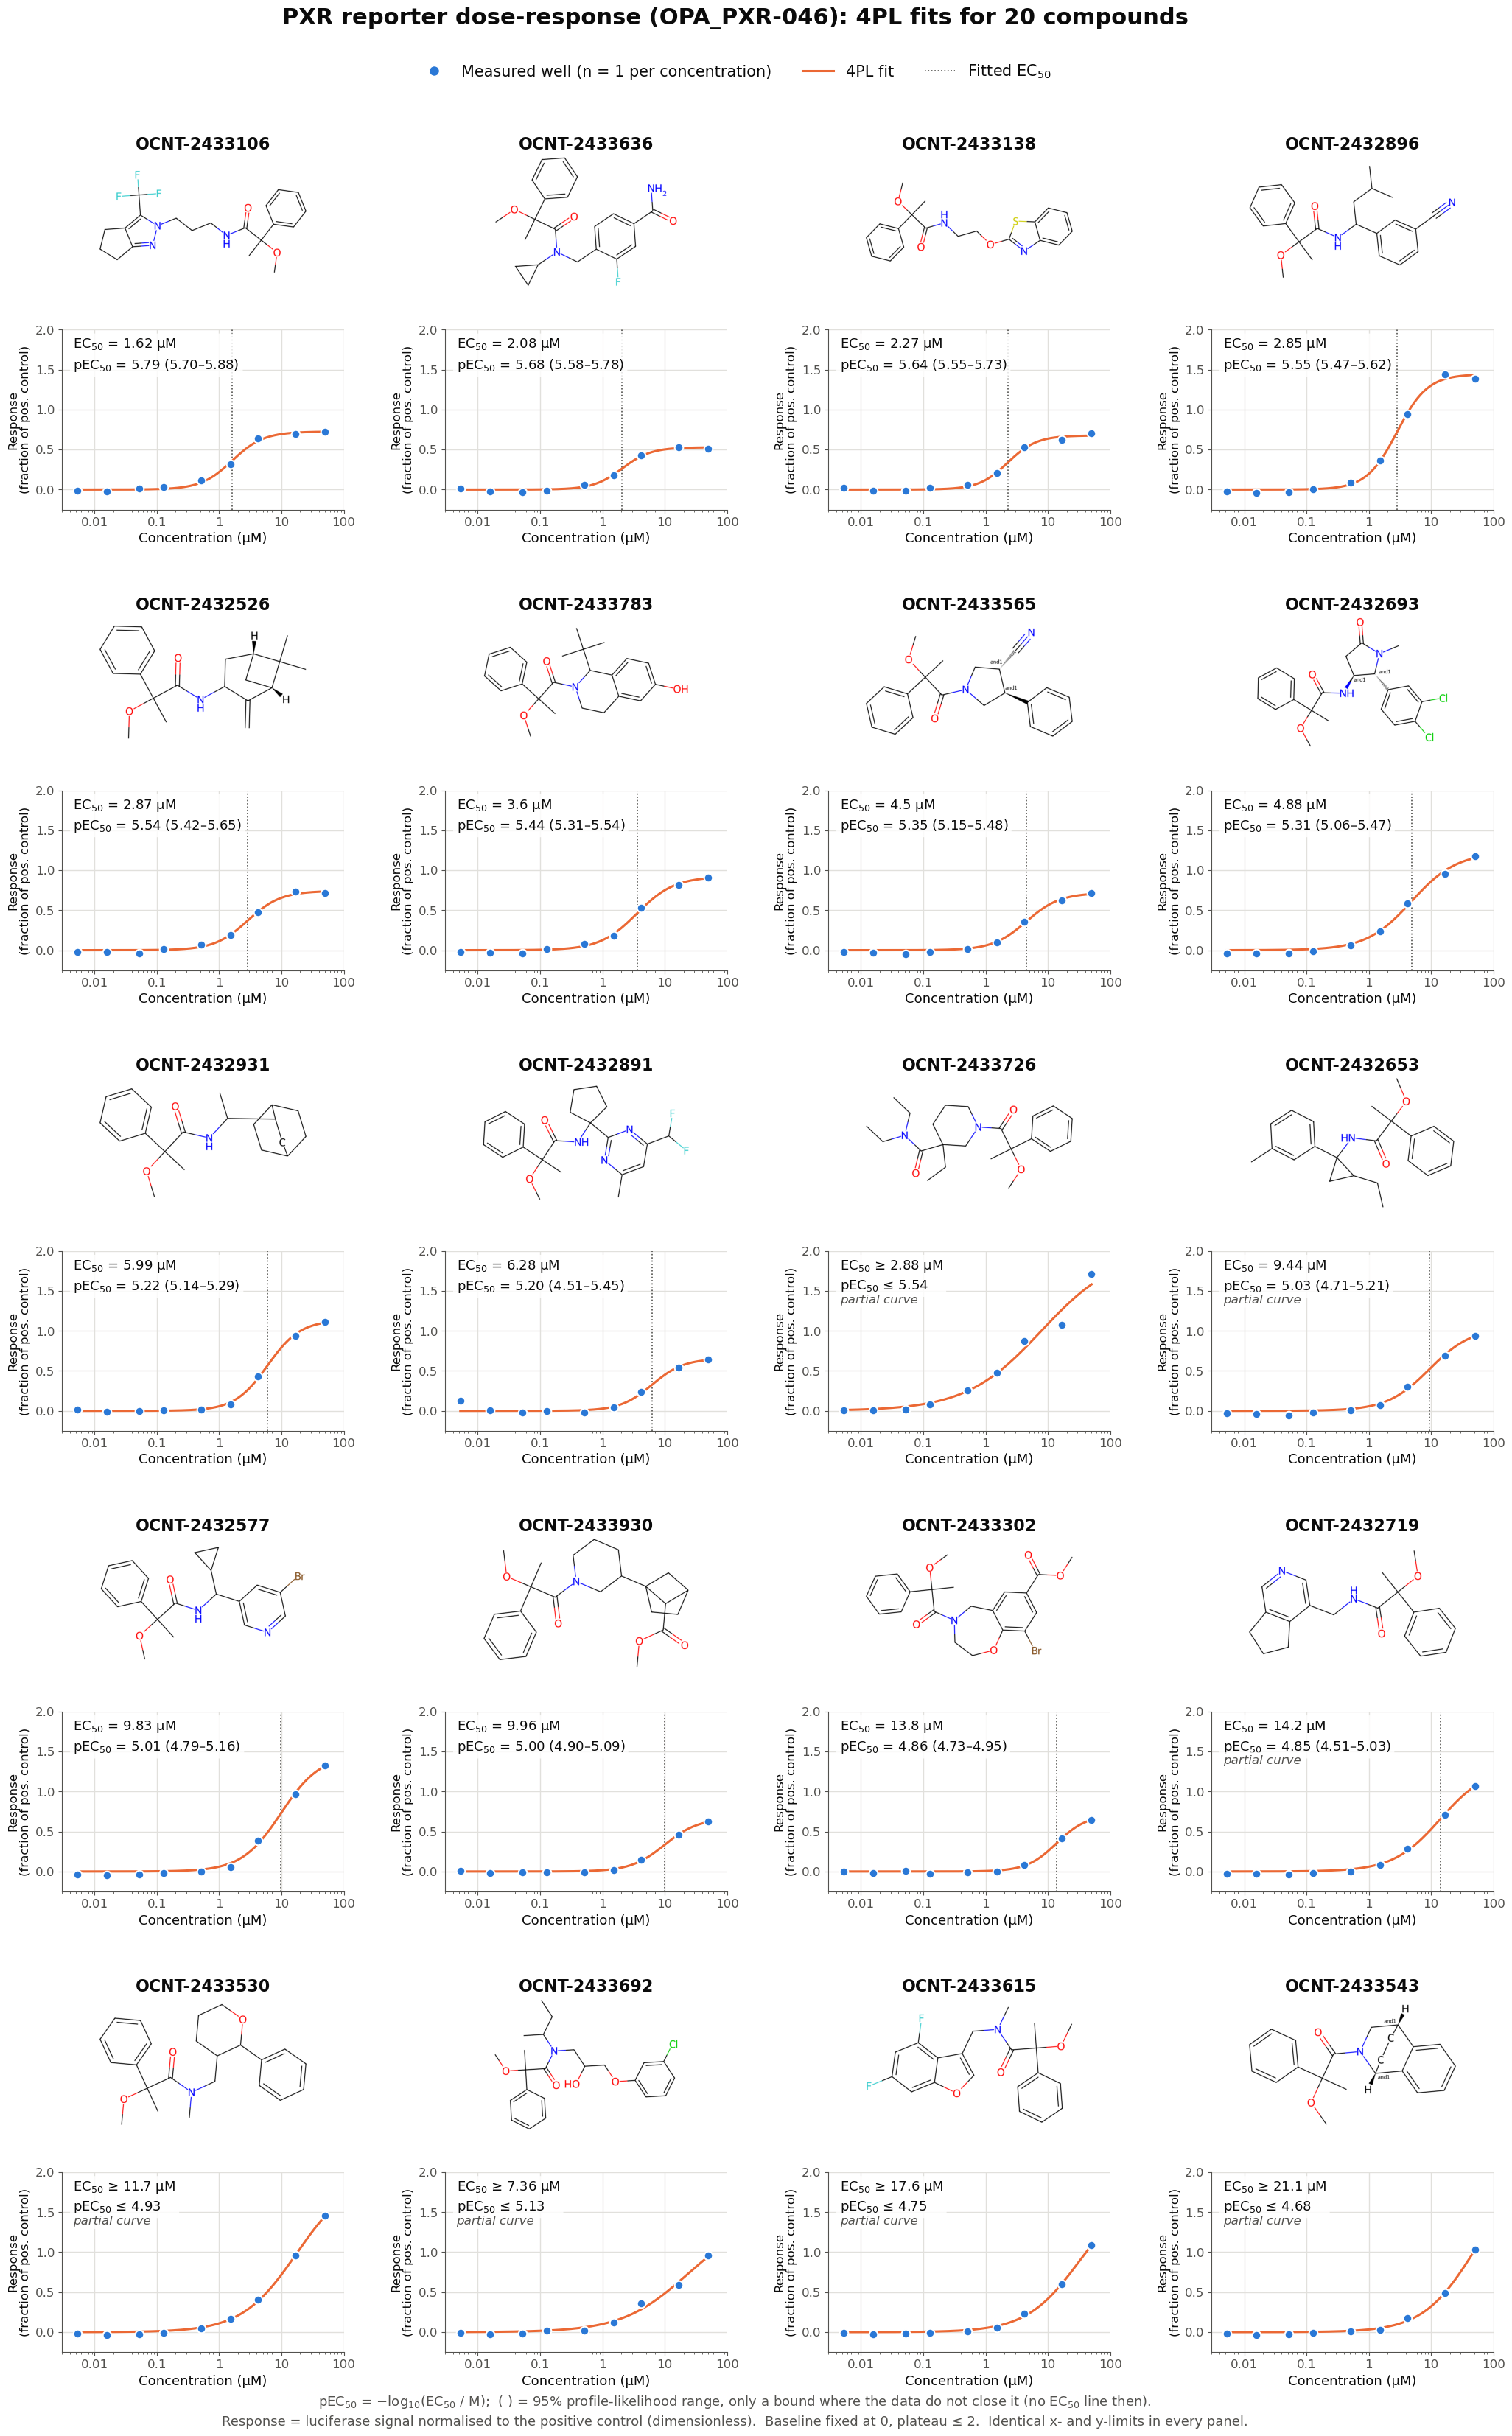

In [10]:
# --- shared axis limits for every panel
XLIM = (3e-3, 1e2)                                   # µM; the data span 0.005 – 50 µM
y_all = wells.luci_norm
YLIM = (np.floor((y_all.min() - 0.03) / 0.25) * 0.25,  # round outwards to 0.25 steps
        np.ceil((y_all.max() + 0.10) / 0.25) * 0.25)
YTICKS = np.arange(np.ceil(YLIM[0] / 0.5) * 0.5, YLIM[1] + 1e-9, 0.5)


def draw_structure(ax, smiles, title):
    # RDKit 2D depiction (large atom labels, thick bonds) with the compound ID as a bold heading.
    mol = Chem.MolFromSmiles(smiles)
    assert mol is not None, f"bad SMILES for {title}"
    drawer = rdMolDraw2D.MolDraw2DCairo(800, 500)
    opts = drawer.drawOptions()
    opts.baseFontSize, opts.bondLineWidth, opts.padding = 0.9, 3, 0.02
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    ax.imshow(Image.open(io.BytesIO(drawer.GetDrawingText())))
    ax.set_axis_off()
    ax.set_title(title, fontsize=16, fontweight="bold", color=INK, pad=6)


def potency_label(fit):
    # Potency text for a panel: EC50 and pEC50 with the 95% range, or only a bound when the range is not closed.
    if np.isfinite(fit.pEC50_lo) and np.isfinite(fit.pEC50_hi):
        return (f"EC$_{{50}}$ = {fit.ec50_uM:.3g} µM\n"
                f"pEC$_{{50}}$ = {fit.pEC50:.2f} ({fit.pEC50_lo:.2f}–{fit.pEC50_hi:.2f})")
    if np.isfinite(fit.pEC50_hi):
        return f"EC$_{{50}}$ ≥ {10 ** (6 - fit.pEC50_hi):.3g} µM\npEC$_{{50}}$ ≤ {fit.pEC50_hi:.2f}"
    return "EC$_{50}$ not bounded"


def draw_curve(ax, g, fit):
    # Measured wells, 4PL fit, fitted EC50 marker and potency annotation on shared axes.
    c, y = g.conc_uM.values, g.luci_norm.values
    xs = np.logspace(np.log10(c.min()), np.log10(c.max()), 200)
    ax.plot(xs, four_pl(np.log10(xs), fit.bottom, fit.top, fit.log_ec50, fit.hill),
            color=ORANGE, lw=2.2, zorder=2)
    closed = np.isfinite(fit.pEC50_lo) and np.isfinite(fit.pEC50_hi)       # 95% range closed on both sides
    if closed and XLIM[0] < fit.ec50_uM < XLIM[1]:
        ax.axvline(fit.ec50_uM, color=MUTED, lw=1.2, ls=":", zorder=1)
    ax.scatter(c, y, s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)

    ax.text(0.04, 0.96, potency_label(fit),
            transform=ax.transAxes, va="top", ha="left", fontsize=13, linespacing=1.4,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    if fit.fit_quality != "full curve":      # quality tag sits under the potency box (clear of the curve)
        ax.text(0.04, 0.76, fit.fit_quality, transform=ax.transAxes, va="top", ha="left",
                fontsize=12, style="italic", color=MUTED,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

    ax.set_xscale("log")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_xticks([0.01, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(YTICKS)
    ax.set_xlabel("Concentration (µM)")
    ax.set_ylabel("Response\n(fraction of pos. control)", fontsize=12)


n_cols = 4
n_rows = int(np.ceil(len(fits) / n_cols))
fig = plt.figure(figsize=(21, 6.7 * n_rows), facecolor="white")
outer = fig.add_gridspec(n_rows, n_cols, hspace=0.30, wspace=0.36,
                         left=0.065, right=0.99, top=0.925, bottom=0.035)

for i, fit in fits.iterrows():
    inner = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // n_cols, i % n_cols],
                                    height_ratios=[1.3, 1.75], hspace=0.26)
    draw_structure(fig.add_subplot(inner[0]), fit.smiles, fit.molecule_name)
    draw_curve(fig.add_subplot(inner[1]), wells[wells.molecule_name == fit.molecule_name], fit)

fig.suptitle("PXR reporter dose-response (OPA_PXR-046): 4PL fits for 20 compounds",
             fontsize=22, fontweight="bold", y=0.985)
fig.legend(handles=[
    Line2D([], [], marker="o", ls="", color=BLUE, markeredgecolor="white", markersize=10, label="Measured well (n = 1 per concentration)"),
    Line2D([], [], color=ORANGE, lw=2.2, label="4PL fit"),
    Line2D([], [], color=MUTED, lw=1.2, ls=":", label="Fitted EC$_{50}$"),
], loc="upper center", bbox_to_anchor=(0.5, 0.968), ncol=3, frameon=False, fontsize=15)
fig.text(0.5, 0.004, "pEC$_{50}$ = −log$_{10}$(EC$_{50}$ / M);  ( ) = 95% profile-likelihood range, only a bound where the data do not close it "
         "(no EC$_{50}$ line then).\n"
         "Response = luciferase signal normalised to the positive control (dimensionless).  Baseline fixed at 0, plateau ≤ 2.  "
         "Identical x- and y-limits in every panel.",
         ha="center", va="bottom", fontsize=13, color=MUTED, linespacing=1.5)

FIGS.mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(FIGS / f"pxr_046_dose_response_20cpds.{ext}", dpi=150, facecolor="white")
plt.show()

## 10. Cross-check against the authors' published fits
The authors' EC₅₀ values come from their own pipeline on the same wells. Points near the dashed identity line mean my 4PL fit agrees with theirs; large offsets usually mark partial curves, where EC₅₀ depends on the extrapolated plateau (the extreme cases are the fits flagged `top_at_bound`). Hollow points are fits for which only a bound on pEC₅₀ is reported; the plotted value is the fitted one.

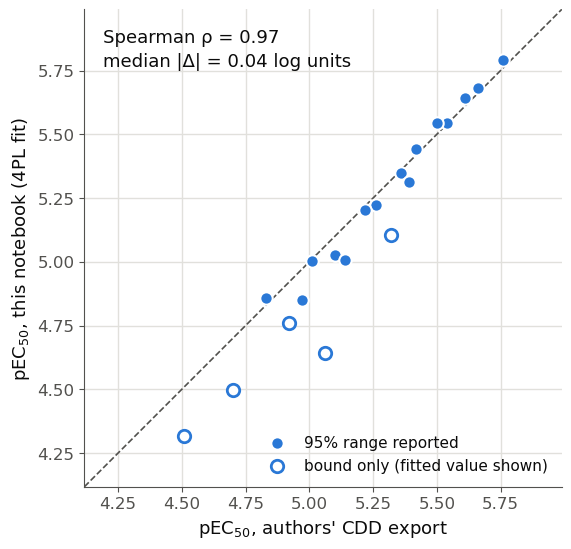

In [11]:
fig2, ax = plt.subplots(figsize=(6.5, 6.2), facecolor="white")
lim = (fits[["pEC50", "author_pEC50"]].min().min() - 0.2, fits[["pEC50", "author_pEC50"]].max().max() + 0.2)
ax.plot(lim, lim, color=MUTED, lw=1.2, ls="--", zorder=1)
closed = fits.pEC50_lo.notna() & fits.pEC50_hi.notna()      # 95% range closed on both sides
ax.scatter(fits.author_pEC50[closed], fits.pEC50[closed], s=80, color=BLUE, edgecolor="white", linewidth=1.5,
           zorder=3, label="95% range reported")
ax.scatter(fits.author_pEC50[~closed], fits.pEC50[~closed], s=80, facecolor="white", edgecolor=BLUE, linewidth=2,
           zorder=3, label="bound only (fitted value shown)")
if (~closed).any():
    ax.legend(loc="lower right", frameon=False, fontsize=11)
ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect("equal")
ax.set_xlabel("pEC$_{50}$, authors' CDD export")
ax.set_ylabel("pEC$_{50}$, this notebook (4PL fit)")

rho = stats.spearmanr(fits.pEC50, fits.author_pEC50).statistic
ax.text(0.04, 0.96, f"Spearman ρ = {rho:.2f}\nmedian |Δ| = {fits.delta_pEC50.abs().median():.2f} log units",
        transform=ax.transAxes, va="top", fontsize=13, linespacing=1.4)
plt.show()

## Notes and limitations
- **One well per concentration** (no replicates), so intervals reflect scatter around the curve only.
- **Partial curves:** where the top concentration (50 µM) is on the rising part of the curve, EC₅₀ depends on the extrapolated plateau; these are labelled in the plots and in `fit_quality`. For fits whose plateau is capped (`top_at_bound = True`) the weak-potency end of the interval is set by the assumed cap, not by the data, so only a bound on pEC₅₀ is reported.
- **Fixed baseline and plateau cap:** the baseline is held at the negative-control level (0) and the plateau is capped at 2 × the positive control (the largest Emax the authors fitted in the library is 1.77). These are modelling choices; a different cap changes the EC₅₀ of capped fits.
- **Authors' fits are not ground truth:** they use the same kind of curve, report EC₅₀ values far above the top concentration (no censoring) and pass confidence intervals up to ~2.6 log units wide.
- **Crude library samples:** the 046 compounds were tested as crude, yield-uncorrected reaction mixtures, so potencies are *apparent* values. The authors' CAD yield correction (described in the blog post) is not applied here.
- **Selection** is by rule (step 4), not a random or exhaustive sample of the library.
